# plot_maps — multi-model SSP5-8.5 and G6sulfur temperature maps

Python port of `plot_maps.m`. Combines the 6 GeoMIP models with SOCOL (as a
7th), regrids each (G6sulfur−SSP2-4.5) and (SSP5-8.5−SSP2-4.5) delta map onto a
common 2° grid, and plots the multi-model mean and standard error, with
stippling where fewer than ⌈7·0.66⌉ = 5 models agree on the sign of the
G6sulfur response.

`map_plots_GeoMIP.mat` is an **external** parent-folder input → read as `.mat`.
`map_plots_GeoMIP_SOCOL` is *created in this folder* (`save_SOCOL`) → read from
`data_py/*.npz`. The `plot_single` per-model block is `False`, so it (and the
unused T0/T1/T2 gradients) are omitted.

In [1]:
import sys, os
import os as _os
_r = _os.getcwd()
while not _os.path.isdir(_os.path.join(_r, "python")) and _os.path.dirname(_r) != _r:
    _r = _os.path.dirname(_r)
_os.chdir(_r)   # notebooks live in j_notebooks/; anchor to project root
sys.path.insert(0, "python")
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import mat_utils as mu
from mat_utils import brewermap, interp2, worldmap, pcolorm, geoshow_coastlines

m = mu.loadmat("../GeoMIP_G6Sulfur/map_plots_GeoMIP.mat")
LATm, LONm, x_map = m["LAT"], m["LON"], m["x_map_20"]    # (1,6),(1,6),(4,6)
S = mu.load_npz("map_plots_GeoMIP_SOCOL")
lat_SOCOL = S["lat_SOCOL"].ravel(); lon_SOCOL = S["lon_SOCOL"].ravel()
x_map_S = S["x_map_20_SOCOL"]                            # (1,4)

# extend to 7 models
LAT = [LATm[0, i].ravel() for i in range(6)] + [lat_SOCOL]
LON = [LONm[0, i].ravel() for i in range(6)] + [lon_SOCOL]
x_map_20 = np.empty((4, 7), dtype=object)
x_map_20[:, :6] = x_map
for im in range(4):
    x_map_20[im, 6] = np.asarray(x_map_S[0, im])

## Regrid the 7 models onto a 2° grid

In [2]:
lat_int1 = np.arange(-90, 91, 2.0)
lon_int1 = np.arange(0, 361, 2.0)
nlat, nlon = lat_int1.size, lon_int1.size
nm = 7
sulf_int = np.full((nlat, nlon, nm), np.nan)
ssp_int = np.full((nlat, nlon, nm), np.nan)

for im in range(nm):
    lat = LAT[im]; lon = LON[im]; lon_ext = np.append(lon, 360.0)
    def regrid(delta):
        d = np.vstack([delta, delta[0:1, :]])
        return interp2(lon_ext, lat, d.T, lon_int1, lat_int1, "linear", np.nan)
    sulf_int[:, :, im] = regrid(x_map_20[0, im] - x_map_20[3, im])
    ssp_int[:, :, im] = regrid(x_map_20[2, im] - x_map_20[3, im])

sulf_delta_all1 = np.nanmean(sulf_int, axis=2)
ssp5_delta_all1 = np.nanmean(ssp_int, axis=2)
sulf_delta_std1 = np.nanstd(sulf_int, axis=2, ddof=1) / np.sqrt(nm)
ssp5_delta_std1 = np.nanstd(ssp_int, axis=2, ddof=1) / np.sqrt(nm)

## Sign-agreement stippling for the G6sulfur mean

In [3]:
sulf_agree = np.zeros((nlat, nlon))
for im in range(nm):
    f = sulf_int[:, :, im]
    sulf_agree += (np.sign(f) == np.sign(sulf_delta_all1)).astype(float)
thresh = int(np.ceil(nm * 0.66))     # = 5
stip = sulf_agree < thresh
LONg, LATg = np.meshgrid(lon_int1, lat_int1)
stip_lon = LONg[stip]; stip_lat = LATg[stip]

## Figure: SSP5-8.5 and G6sulfur, mean & standard error

/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


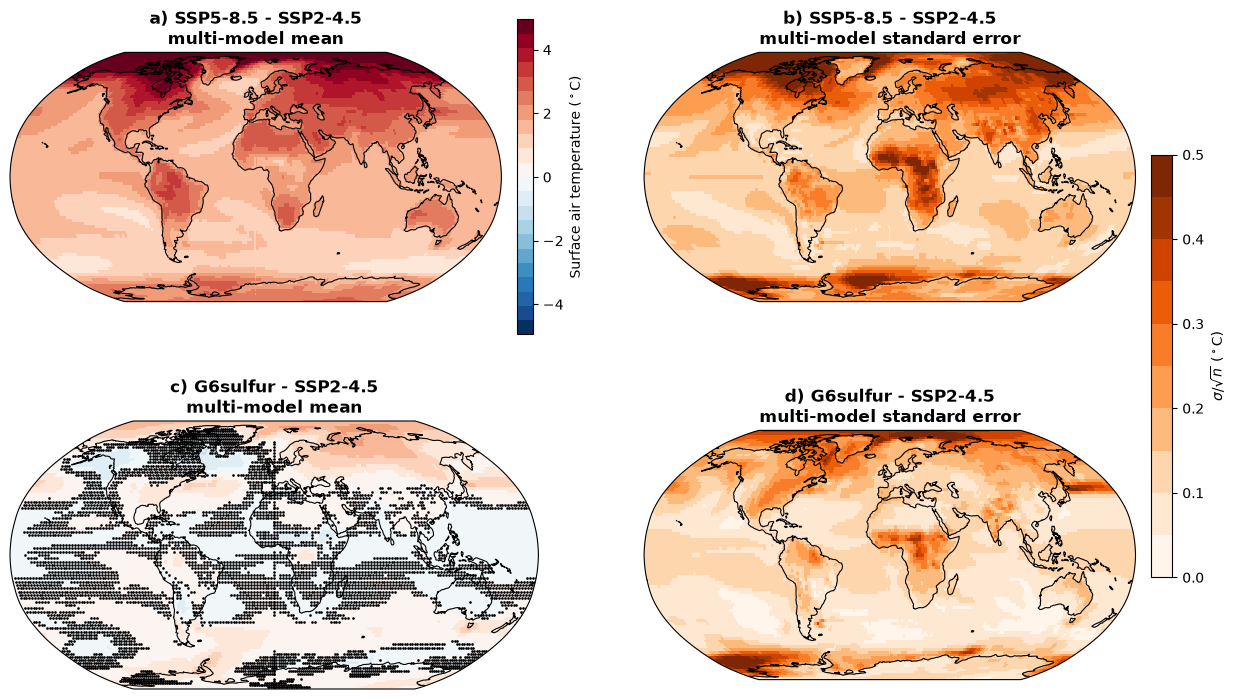

/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


saved py_outputs/maps_mean.png; stippled points: 5481


In [4]:
fc = brewermap(22, "*RdBu"); mmin, mmax = -1.65 * 3, 1.65 * 3
fca = brewermap(10, "Oranges"); mmax2 = 0.5

fig, axes = plt.subplots(2, 2, figsize=(15, 9),
                         subplot_kw={"projection": ccrs.Robinson()})
# a) SSP5-8.5 mean
ax = axes[0, 0]; mu.worldmap(ax=ax)
mp = pcolorm(ax, lat_int1, lon_int1, ssp5_delta_all1, cmap=fc, vmin=mmin, vmax=mmax)
geoshow_coastlines(ax); ax.set_title("a) SSP5-8.5 - SSP2-4.5\nmulti-model mean", fontweight="bold")
fig.colorbar(mp, ax=ax, orientation="vertical", fraction=0.04, pad=0.03,
             label=r"Surface air temperature ($^\circ$C)")
# b) SSP5-8.5 SE
ax = axes[0, 1]; mu.worldmap(ax=ax)
mp2 = pcolorm(ax, lat_int1, lon_int1, np.abs(ssp5_delta_std1), cmap=fca, vmin=0, vmax=mmax2)
geoshow_coastlines(ax); ax.set_title("b) SSP5-8.5 - SSP2-4.5\nmulti-model standard error", fontweight="bold")
# c) G6sulfur mean + stipple
ax = axes[1, 0]; mu.worldmap(ax=ax)
mp = pcolorm(ax, lat_int1, lon_int1, sulf_delta_all1, cmap=fc, vmin=mmin, vmax=mmax)
ax.scatter(np.where(stip_lon > 180, stip_lon - 360, stip_lon), stip_lat, s=0.8, c="k",
           transform=ccrs.PlateCarree())
geoshow_coastlines(ax); ax.set_title("c) G6sulfur - SSP2-4.5\nmulti-model mean", fontweight="bold")
# d) G6sulfur SE
ax = axes[1, 1]; mu.worldmap(ax=ax)
mp2 = pcolorm(ax, lat_int1, lon_int1, np.abs(sulf_delta_std1), cmap=fca, vmin=0, vmax=mmax2)
geoshow_coastlines(ax); ax.set_title("d) G6sulfur - SSP2-4.5\nmulti-model standard error", fontweight="bold")
fig.colorbar(mp2, ax=axes[:, 1], orientation="vertical", fraction=0.04, pad=0.03,
             label=r"$\sigma / \sqrt{n}$ ($^\circ$C)")
plt.show()
os.makedirs("py_outputs", exist_ok=True)
fig.savefig("py_outputs/maps_mean.png", dpi=300, bbox_inches="tight")
print("saved py_outputs/maps_mean.png; stippled points:", int(stip.sum()))